In [89]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
import transformers
import inspect
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling,
    EarlyStoppingCallback
)
from torch.utils.data import Dataset

In [90]:
class Config:

    MODEL_NAME = "distilgpt2"
    DATASET_NAME = "tiny_shakespeare"

    OUTPUT_DIR = "./gpt2-text-generator"

    MAX_LENGTH = 128
    BATCH_SIZE = 8
    EPOCHS = 5
    LEARNING_RATE = 5e-5

    TEST_SIZE = 0.1
    SEED = 42

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


print("Device:", Config.DEVICE)
print("Model:", Config.MODEL_NAME)


Device: cuda
Model: distilgpt2


In [91]:
dataset = load_dataset("Trelis/tiny-shakespeare")

print(dataset)
print("\nTraining sample:\n")
print(dataset["train"][0])


DatasetDict({
    train: Dataset({
        features: ['Text'],
        num_rows: 472
    })
    test: Dataset({
        features: ['Text'],
        num_rows: 49
    })
})

Training sample:

{'Text': "First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved rather to die than to famish?\n\nAll:\nResolved. resolved.\n\nFirst Citizen:\nFirst, you know Caius Marcius is chief enemy to the people.\n\nAll:\nWe know't, we know't.\n\nFirst Citizen:\nLet us kill him, and we'll have corn at our own price.\nIs't a verdict?\n\nAll:\nNo more talking on't; let it be done: away, away!\n\nSecond Citizen:\nOne word, good citizens.\n\nFirst Citizen:\nWe are accounted poor citizens, the patricians good.\nWhat authority surfeits on would relieve us: if they\nwould yield us but the superfluity, while it were\nwholesome, we might guess they relieved us humanely;\nbut they think we are too dear: the leanness that\nafflicts us, the object of o

In [92]:
train_data = dataset["train"]
print("Total samples:", len(train_data))
print("Columns:", train_data.column_names)
print("\nFirst sample:")
print(train_data[0])
print("\nFeatures:")
print(train_data.features)


Total samples: 472
Columns: ['Text']

First sample:
{'Text': "First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved rather to die than to famish?\n\nAll:\nResolved. resolved.\n\nFirst Citizen:\nFirst, you know Caius Marcius is chief enemy to the people.\n\nAll:\nWe know't, we know't.\n\nFirst Citizen:\nLet us kill him, and we'll have corn at our own price.\nIs't a verdict?\n\nAll:\nNo more talking on't; let it be done: away, away!\n\nSecond Citizen:\nOne word, good citizens.\n\nFirst Citizen:\nWe are accounted poor citizens, the patricians good.\nWhat authority surfeits on would relieve us: if they\nwould yield us but the superfluity, while it were\nwholesome, we might guess they relieved us humanely;\nbut they think we are too dear: the leanness that\nafflicts us, the object of our misery, is as an\ninventory to particularise their abundance; our\nsufferance is a gain to them Let us revenge this with\nour pikes, er

In [93]:

tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

sample = "To be, or not to be, that is the question."
tokens = tokenizer(sample)
print("Original text:", sample)
print("\nToken IDs:", tokens["input_ids"])
print("\nTokens:", tokenizer.convert_ids_to_tokens(tokens["input_ids"]))


Original text: To be, or not to be, that is the question.

Token IDs: [2514, 307, 11, 393, 407, 284, 307, 11, 326, 318, 262, 1808, 13]

Tokens: ['To', 'Ġbe', ',', 'Ġor', 'Ġnot', 'Ġto', 'Ġbe', ',', 'Ġthat', 'Ġis', 'Ġthe', 'Ġquestion', '.']


In [94]:
print(dataset)
print(dataset["train"].column_names)
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['Text'],
        num_rows: 472
    })
    test: Dataset({
        features: ['Text'],
        num_rows: 49
    })
})
['Text']
{'Text': "First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved rather to die than to famish?\n\nAll:\nResolved. resolved.\n\nFirst Citizen:\nFirst, you know Caius Marcius is chief enemy to the people.\n\nAll:\nWe know't, we know't.\n\nFirst Citizen:\nLet us kill him, and we'll have corn at our own price.\nIs't a verdict?\n\nAll:\nNo more talking on't; let it be done: away, away!\n\nSecond Citizen:\nOne word, good citizens.\n\nFirst Citizen:\nWe are accounted poor citizens, the patricians good.\nWhat authority surfeits on would relieve us: if they\nwould yield us but the superfluity, while it were\nwholesome, we might guess they relieved us humanely;\nbut they think we are too dear: the leanness that\nafflicts us, the object of our misery,

In [95]:

train_texts = dataset["train"]["Text"]
test_texts = dataset["test"]["Text"]

train_corpus = "\n".join(train_texts)
test_corpus = "\n".join(test_texts)

print("Training characters:", len(train_corpus))
print("Testing characters:", len(test_corpus))


Training characters: 1222825
Testing characters: 119068


In [96]:

train_tokens = tokenizer(
    train_corpus,
    add_special_tokens=False
)["input_ids"]

test_tokens = tokenizer(
    test_corpus,
    add_special_tokens=False
)["input_ids"]

print("Training tokens:", len(train_tokens))
print("Testing tokens:", len(test_tokens))


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (369111 > 1024). Running this sequence through the model will result in indexing errors


Training tokens: 369111
Testing tokens: 38716


In [97]:

def create_blocks(token_ids, block_size=128):

    blocks = []

    for i in range(0, len(token_ids) - block_size + 1, block_size):
        blocks.append(token_ids[i:i + block_size])

    return blocks


train_blocks = create_blocks(train_tokens, Config.MAX_LENGTH)
test_blocks = create_blocks(test_tokens, Config.MAX_LENGTH)

print("Training blocks:", len(train_blocks))
print("Testing blocks:", len(test_blocks))


Training blocks: 2883
Testing blocks: 302


In [98]:
class GPTDataset(Dataset):

    def __init__(self, blocks):
        self.blocks = blocks

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, index):
        input_ids = torch.tensor(
            self.blocks[index],
            dtype=torch.long
        )

        return {
            "input_ids": input_ids,
            "labels": input_ids.clone()
        }


train_dataset = GPTDataset(train_blocks)
test_dataset = GPTDataset(test_blocks)

print("Training examples:", len(train_dataset))
print("Testing examples:", len(test_dataset))
print("Example shape:", train_dataset[0]["input_ids"].shape)


Training examples: 2883
Testing examples: 302
Example shape: torch.Size([128])


In [99]:

model = AutoModelForCausalLM.from_pretrained(
    Config.MODEL_NAME
)

model.config.pad_token_id = tokenizer.pad_token_id

model.to(Config.DEVICE)

print("Model loaded successfully!")
print("Device:", Config.DEVICE)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Model loaded successfully!
Device: cuda
Trainable parameters: 81912576


In [100]:


training_args = TrainingArguments(

    output_dir=Config.OUTPUT_DIR,

    num_train_epochs=5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,               

    lr_scheduler_type="linear",

    weight_decay=0.01,        

    max_grad_norm=1.0,    

    eval_strategy="epoch",
    save_strategy="epoch",

    logging_steps=10,

    fp16=torch.cuda.is_available(),

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    save_total_limit=2,

    report_to="none",
    seed=Config.SEED
)

print("training configuration ready!")


training configuration ready!


In [101]:

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

print("Data collator ready!")


Data collator ready!


In [102]:

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=data_collator,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2)
    ]
)

print("Trainer initialized!")


Trainer initialized!


In [103]:

train_result = trainer.train()

print("\nTraining completed!")
print("Training loss:", train_result.training_loss)


Epoch,Training Loss,Validation Loss
1,3.852170,3.797178
2,3.811344,3.722913
3,3.701497,3.692197
4,3.645490,3.680093
5,3.681329,3.678047


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].



Training completed!
Training loss: 3.801387019710646


In [104]:

eval_results = trainer.evaluate()

print("Evaluation Results:")
print(eval_results)

print("\nTest Perplexity:", np.exp(eval_results["eval_loss"]))


Training Loss,Validation Loss,Epoch
3.681329,3.678047,5


Evaluation Results:
{'eval_loss': 3.6780471801757812}

Test Perplexity: 39.56904735495082


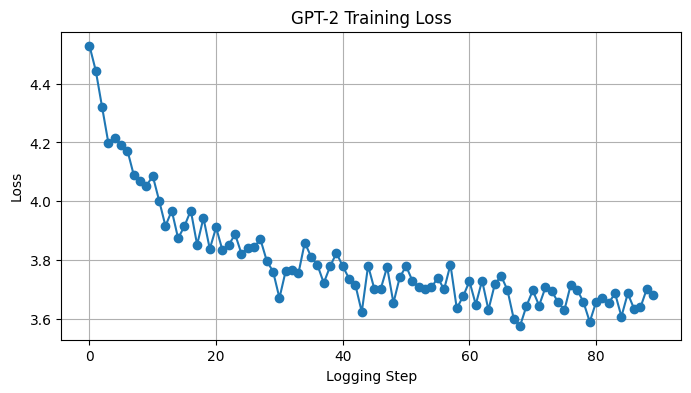

In [105]:

logs = trainer.state.log_history

train_losses = [
    log["loss"] for log in logs if "loss" in log
]

plt.figure(figsize=(8, 4))
plt.plot(train_losses, marker="o")

plt.title("GPT-2 Training Loss")
plt.xlabel("Logging Step")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


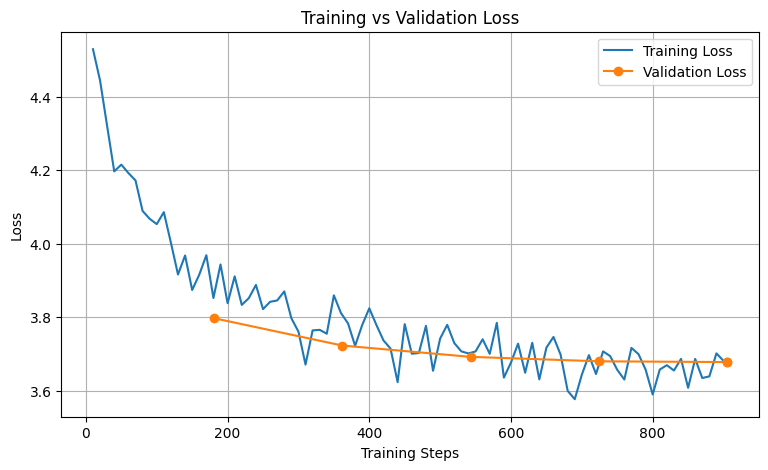

In [106]:
logs = trainer.state.log_history

train_steps, train_losses = [], []
eval_steps, eval_losses = [], []

for log in logs:
    if "loss" in log:
        train_steps.append(log["step"])
        train_losses.append(log["loss"])

    if "eval_loss" in log:
        eval_steps.append(log["step"])
        eval_losses.append(log["eval_loss"])

plt.figure(figsize=(9, 5))

plt.plot(train_steps, train_losses, label="Training Loss")
plt.plot(eval_steps, eval_losses, marker="o", label="Validation Loss")

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid()
plt.show()

In [107]:
model = trainer.model
model.eval()
model.to(Config.DEVICE)
print("Model ready for text generation!")


Model ready for text generation!


In [108]:

prompt = "To be, or not to be"

inputs = tokenizer(prompt, return_tensors="pt").to(Config.DEVICE)

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=True,
        pad_token_id=tokenizer.eos_token_id
    )

generated_text = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print(generated_text)


To be, or not to be, that he cannot make himself. Let him take his oath, if he be, thou wilt make him.

DUKE VINCENTIO:
I think there will be, a man in France, you think?

ROMEO:
I will not be.

DUKE VINCENTIO:

ROMEO:
I think there was a man in France, you know, before I made him,
but here comes Rome and his army


In [109]:

temperatures = [0.5, 0.8, 1.0]

for temp in temperatures:

    outputs = model.generate(
        **inputs,
        max_new_tokens=60,
        do_sample=True,
        temperature=temp,
        pad_token_id=tokenizer.eos_token_id
    )

    print(f"\nTemperature: {temp}")
    print(tokenizer.decode(outputs[0], skip_special_tokens=True))
    print("-" * 60)



Temperature: 0.5
To be, or not to be.

First Gentleman:
This is my lord; I am the king.

First Gentleman:
This is my lord; I am the king.

First Gentleman:
I am the king.

First Gentleman:
I am the king.

First Gentleman:
------------------------------------------------------------

Temperature: 0.8
To be, or not to be;
I'd come to the castle: my father,
His father, I will see you.

GLOUCESTER:
What was I here? Can't you see your father's face?

KING RICHARD II:
Not there, sir.


------------------------------------------------------------

Temperature: 1.0
To be, or not to be.‏

HENRY BOLINGBROKE:
This is no longer your name, nor your name.
Your brother died; and the enemy of theirs, your brother,
But that I, his brother-in-law,
You took your brother's death
------------------------------------------------------------


In [110]:

sampling_settings = [
    {"top_k": 20, "top_p": 1.0},
    {"top_k": 50, "top_p": 1.0},
    {"top_k": 0, "top_p": 0.9},
    {"top_k": 0, "top_p": 0.95}
]

for settings in sampling_settings:

    outputs = model.generate(
        **inputs,
        max_new_tokens=60,
        do_sample=True,
        temperature=0.8,
        top_k=settings["top_k"],
        top_p=settings["top_p"],
        pad_token_id=tokenizer.eos_token_id
    )

    print("\nSettings:", settings)
    print(tokenizer.decode(outputs[0], skip_special_tokens=True))
    print("-" * 60)



Settings: {'top_k': 20, 'top_p': 1.0}
To be, or not to be.

HENRY BOLINGBROKE:
I'll give you, but for the sake of my life,
So much so as to make you a man
That, by my grace and a man's love.

HENRY BOLINGBROKE
------------------------------------------------------------

Settings: {'top_k': 50, 'top_p': 1.0}
To be, or not to be.

Nurse:
Well, it is a matter of course, with her.

SICINIUS:
She is not, nor is she a woman.

Nurse:
She is not, nor is she a woman.

SICINI
------------------------------------------------------------

Settings: {'top_k': 0, 'top_p': 0.9}
To be, or not to be, good, good.

KING RICHARD III:
Yes, good, good.

KING RICHARD III:
God, good, good, good.

KING RICHARD III:
I'll kill thee, the proud king.

KING RICH
------------------------------------------------------------

Settings: {'top_k': 0, 'top_p': 0.95}
To be, or not to be
these unhappy men: why, I hope not.

DUKE VINCENTIO:
Why is a king, and himself not, and therefore, a child?

DUKE VINCENTIO:
I do thin

In [111]:

outputs = model.generate(
    **inputs,
    max_new_tokens=100,
    do_sample=True,

    temperature=0.8,
    top_k=50,
    top_p=0.95,

    repetition_penalty=1.2,
    no_repeat_ngram_size=3,

    pad_token_id=tokenizer.eos_token_id
)

print(tokenizer.decode(outputs[0], skip_special_tokens=True))


To be, or not to be!
And in this respect have I a word: go and kill; there is no one but myself. Now that the other's gone from me? There must still rest with him again before he dies--he deserves his life for all of it.--Hath thou hast done my duty so well as many more worthy deeds thus far!--I'll tell you hence how much time hath paid up by thee now on your behalf here at Gauntlande County-of Norfolk county alone shall bear thy
